# Industry Project: An EDA Report a Manager Can Act On (Production-Style)

> **Who is this notebook for?** Someone who knows a little pandas and wants to see how a data analyst at a company turns a messy sales export into numbers and recommendations a manager trusts.
> No statistics background is needed: every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from `07_eda.ipynb`

| `07_eda.ipynb` | This notebook |
|---|---|
| Explores a clean public dataset (Titanic) to *understand the data* | Answers **business questions** from a manager with a messy **transactions** export |
| Generic steps: univariate, bivariate, correlation, profiling | Analyst workflow: **data-quality report with revenue impact**, **KPI definitions**, like-for-like trends, **cohort retention**, segments, **Pareto/ABC**, a **statistical check of a claim** |
| Charts for the analyst | Charts for **stakeholders**: one message per chart, titles that state the finding, units on every axis |
| Ends with observations | Ends with an **auto-generated findings & recommendations memo** plus QA checks on the numbers |

---

### The business problem

You are the analyst at **NordHome**, a (fictional) online home-goods shop selling through its website, its app and a marketplace. It is mid-December 2025 and the Head of E-commerce writes:

> *"I'm presenting the 2025 review to the leadership team next week. I need: how we did vs last year, what is driving it, whether our customers come back, where the money is concentrated, and whether the new **loyalty program** (launched July) works: marketing says members spend about 20% more per order. One page, please, with recommendations."*

Constraints that make this realistic:
- The data warehouse export runs **until 15 December 2025** (the year is not over).
- The export is **messy**: duplicate rows from a double ETL load, returns as negative lines, test orders, price typos, guest checkouts without a customer id, inconsistent region spelling.
- The manager will **act on** these numbers (budget, staffing, stock), so every number must be defined, reconciled and reproducible.

### Table of Contents
1. Setup: imports and the report configuration
2. The data: a warehouse export (simulated)
3. Data-quality report (with revenue impact)
4. Cleaning, and a revenue bridge from raw to clean
5. KPI definitions (agree on them before computing)
6. Year-over-year, like for like
7. Monthly trends
8. Cohort retention: do customers come back?
9. Segment breakdowns: category, channel, region
10. Pareto / ABC analysis: where is the money concentrated?
11. Checking a claim: "loyalty members spend 20% more"
12. The auto-generated memo for the manager
13. QA checks on the report numbers
14. Summary, exercises and resources

---
## 1. Setup: imports and the report configuration

Report parameters (the extract date, the comparison windows, thresholds) live in one place. When the manager asks for the same report next month, you change the config and re-run, instead of editing numbers spread across 30 cells.

In [1]:
import logging                                # status messages with timestamps
import tempfile                               # the memo is written to a temporary folder, not into the repo
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt               # charts
import matplotlib.ticker as mticker           # axis formatting ($, %)
import numpy as np                            # numbers and random generators
import pandas as pd                           # tables
from IPython.display import Markdown, display # render the memo as formatted text
from scipy import stats                       # statistical tests

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("eda_report")
pd.set_option("display.width", 140)

# One consistent, colour-blind-friendly palette; "2025" is always blue, "2024" always grey
COLORS = {"2025": "#2a78d6", "2024": "#a3a29b", "accent": "#eb6834", "good": "#1baf7a", "bad": "#e34948"}


@dataclass(frozen=True)
class ReportConfig:
    """Everything that defines this report run."""
    extract_end: str = "2025-12-15"           # last day in the warehouse export
    current_year: int = 2025
    previous_year: int = 2024
    loyalty_launch: str = "2025-07-01"
    price_outlier_factor: float = 20.0        # unit price > 20x the SKU's median price = typo
    abc_cutoffs: tuple = (0.80, 0.95)         # A = first 80% of revenue, B = next 15%, C = rest
    n_bootstrap: int = 2000
    seed: int = 42


CFG = ReportConfig()
print(CFG)

ReportConfig(extract_end='2025-12-15', current_year=2025, previous_year=2024, loyalty_launch='2025-07-01', price_outlier_factor=20.0, abc_cutoffs=(0.8, 0.95), n_bootstrap=2000, seed=42)


---
## 2. The data: a warehouse export (simulated)

In a real company you would run two SQL queries against the data warehouse, for example:

```sql
-- order lines (one row per product in an invoice), returns included as negative quantities
SELECT invoice_no, invoice_date, customer_id, sku, category, quantity, unit_price,
       channel, region, loyalty_member
FROM sales.order_lines WHERE invoice_date >= '2024-01-01';

-- customer master data (one row per customer)
SELECT customer_id, signup_date FROM crm.customers;
```

So that the notebook runs anywhere, we simulate both tables with a fixed seed. The structure follows the well-known **UCI "Online Retail II"** dataset (invoices, cancellations starting with `C`, missing customer ids), plus the problems an analyst meets every week. The generator is long; you can skip its details.

In [2]:
def make_warehouse_export(n_customers: int = 8000, n_skus: int = 300, seed: int = 42,
                          extract_end: str = "2025-12-15") -> tuple[pd.DataFrame, pd.DataFrame]:
    """Simulate (order_lines, customers). Customers exist since 2023; the export starts in 2024."""
    rng = np.random.default_rng(seed)
    months = pd.period_range("2023-01", "2025-12", freq="M")
    n_months = len(months)
    season = np.array([0.8, 0.8, 0.9, 0.95, 1.0, 0.95, 0.9, 0.9, 1.0, 1.05, 1.35, 1.6])   # Nov/Dec peak

    # --- product catalogue: prices by category, a few best-sellers (Zipf-like popularity) ---
    categories = np.array(["Kitchen", "Bedding", "Lighting", "Decor", "Furniture", "Garden"])
    sku_cat = rng.choice(categories, n_skus, p=[0.25, 0.18, 0.15, 0.22, 0.08, 0.12])
    base = pd.Series({"Kitchen": 18, "Bedding": 35, "Lighting": 40, "Decor": 15, "Furniture": 160, "Garden": 25})
    sku_price = (base[sku_cat].to_numpy() * rng.lognormal(0, 0.45, n_skus)).round(2)
    pop = rng.permutation(1 / np.arange(1, n_skus + 1) ** 1.1)
    pop_2025 = pop * np.where(sku_cat == "Garden", 1.35, 1.0) * np.where(sku_cat == "Bedding", 0.8, 1.0)
    pop, pop_2025 = pop / pop.sum(), pop_2025 / pop_2025.sum()

    # --- customers: signup month, purchase rate, basket size, loyalty (engaged customers join more) ---
    weights = np.linspace(1, 2.0, n_months); weights /= weights.sum()
    cohort = rng.choice(n_months, n_customers, p=weights)
    rate = rng.gamma(1.5, 0.4, n_customers)                 # orders per active month
    basket = rng.lognormal(0, 0.5, n_customers)             # how much they buy per order
    lifetime = rng.geometric(1 - rng.beta(7, 2, n_customers))   # months until they stop buying
    region = rng.choice(["North", "South", "East", "West", "International"], n_customers, p=[.28, .24, .2, .18, .1])
    pref = rng.choice(["web", "app", "marketplace"], n_customers, p=[.5, .3, .2])
    joins = rng.random(n_customers) < 1 / (1 + np.exp(-(-1.7 + 1.2 * np.log(rate / 0.6) + 2.5 * np.log(basket))))
    join_date = pd.Timestamp(CFG.loyalty_launch) + pd.to_timedelta(rng.integers(0, 100, n_customers), unit="D")

    # --- customer-month panel -> orders -> lines (all vectorised) ---
    n_active = np.minimum(lifetime, n_months - cohort)
    cust = np.repeat(np.arange(n_customers), n_active)
    offset = np.concatenate([np.arange(k) for k in n_active])
    midx = cohort[cust] + offset
    growth = np.select([months.year[midx] == 2025, months.year[midx] == 2024], [1.10, 1.0], 0.95)
    n_orders = rng.poisson(rate[cust] * season[months.month[midx] - 1] * growth) + (offset == 0)
    o_cust = np.repeat(cust, n_orders)
    o_date = (np.repeat(months.start_time[midx], n_orders)
              + pd.to_timedelta((rng.random(len(o_cust)) * np.repeat(months.days_in_month[midx], n_orders)
                                 * 86400).astype(int), unit="s"))
    keep = (o_date >= "2024-01-01") & (o_date < pd.Timestamp(extract_end) + pd.Timedelta(days=1))
    o_cust, o_date = o_cust[keep], o_date[keep]
    n_ord = len(o_cust)
    member = joins[o_cust] & (o_date >= join_date[o_cust])
    channel = np.where(rng.random(n_ord) < 0.8, pref[o_cust], rng.choice(["web", "app", "marketplace"], n_ord))
    n_lines = rng.poisson(1.5, n_ord) + 1
    line_order = np.repeat(np.arange(n_ord), n_lines)
    is_2025 = o_date.year[line_order] == 2025
    sku = np.where(is_2025, rng.choice(n_skus, len(line_order), p=pop_2025), rng.choice(n_skus, len(line_order), p=pop))
    qty = rng.poisson(0.7 * basket[o_cust[line_order]] * np.where(member[line_order], 1.05, 1.0)) + 1
    # one line per (order, product), like a real order system: same product twice -> quantity added up
    line = pd.DataFrame({"order": line_order, "sku": sku, "qty": qty}).groupby(["order", "sku"], as_index=False)["qty"].sum()
    o, k = line["order"].to_numpy(), line["sku"].to_numpy()
    lines = pd.DataFrame({
        "invoice_no": (500000 + o).astype(str), "invoice_date": o_date[o],
        "customer_id": (10001 + o_cust[o]).astype(str), "sku": [f"SKU{x:04d}" for x in k],
        "category": sku_cat[k], "quantity": line["qty"].to_numpy(), "unit_price": sku_price[k],
        "channel": channel[o], "region": region[o_cust[o]], "loyalty_member": member[o],
    })

    # --- returns: negative lines on a 'C' invoice, more frequent on the marketplace ---
    p_return = np.where(lines["channel"] == "marketplace", 0.10, 0.035)
    ret = lines[rng.random(len(lines)) < p_return].copy()
    ret["invoice_no"] = "C" + ret["invoice_no"]
    ret["invoice_date"] = ret["invoice_date"] + pd.to_timedelta(rng.integers(3, 25, len(ret)), unit="D")
    ret["quantity"] = -ret["quantity"]
    ret = ret[ret["invoice_date"] < pd.Timestamp(extract_end) + pd.Timedelta(days=1)]
    lines = pd.concat([lines, ret], ignore_index=True)

    # --- the mess an analyst meets every week ---
    n = len(lines)
    guest = rng.choice(n, int(0.025 * n), replace=False)
    lines.loc[guest, "customer_id"] = np.nan                                    # guest checkouts
    region_mess = rng.choice(n, 600, replace=False)
    lines.loc[region_mess, "region"] = lines.loc[region_mess, "region"].map(
        {"North": "north", "South": "SOUTH ", "East": "East ", "West": "west", "International": "Intl"})
    lines.loc[rng.choice(n, 200, replace=False), "category"] = np.nan           # missing category
    typo = rng.choice(np.flatnonzero(lines["quantity"] > 0), 15, replace=False)
    lines.loc[typo, "unit_price"] = lines.loc[typo, "unit_price"] * 100         # price typo (missing decimal point)
    test = pd.DataFrame({"invoice_no": [f"T{i}" for i in range(12)],            # QA test orders in production
                         "invoice_date": pd.Timestamp("2025-03-03") + pd.to_timedelta(np.arange(12), unit="D"),
                         "customer_id": "TEST", "sku": "SKU0001", "category": "Kitchen", "quantity": 50,
                         "unit_price": 99.0, "channel": "web", "region": "North", "loyalty_member": False})
    future = lines.sample(4, random_state=seed).assign(invoice_date=pd.Timestamp("2035-01-01"))   # bad timestamps
    lines = pd.concat([lines, test, future, lines.sample(300, random_state=seed + 1)],             # double ETL load
                      ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)

    customers = pd.DataFrame({"customer_id": (10001 + np.arange(n_customers)).astype(str),
                              "signup_date": months.start_time[cohort] + pd.to_timedelta(rng.integers(0, 28, n_customers), unit="D")})
    return lines, customers


raw, customers = make_warehouse_export(extract_end=CFG.extract_end)
print(f"order_lines: {len(raw):,} rows | customers: {len(customers):,} rows")
raw.head()

order_lines: 64,480 rows | customers: 8,000 rows


,invoice_no,invoice_date,customer_id,sku,category,quantity,unit_price,channel,region,loyalty_member
0,503565,2025-04-16 12:21:13,11177,SKU0198,Kitchen,1,12.67,web,North,False
1,520734,2024-11-27 03:23:38,16347,SKU0290,Furniture,2,142.81,marketplace,South,False
2,519200,2024-12-25 03:33:32,15897,SKU0016,Lighting,1,38.91,app,South,False
3,522196,2025-09-24 14:17:01,16761,SKU0136,Garden,2,16.76,app,North,True
4,511298,2025-06-22 13:57:37,13588,SKU0096,Bedding,1,17.03,web,South,False


---
## 3. Data-quality report (with revenue impact)

Before any KPI, an analyst answers: *"Can I trust this export?"* The classic EDA notebook prints missing-value counts. A stakeholder report goes further: for every issue it states **how many rows**, **how much revenue** is affected, and the **decision** taken. Finance will ask exactly these questions when your revenue number differs from theirs.

In [3]:
lines = raw.copy()
lines["line_value"] = lines["quantity"] * lines["unit_price"]            # revenue of the line (negative for returns)
sku_median_price = lines[lines["quantity"] > 0].groupby("sku")["unit_price"].median()
known_regions = {"North", "South", "East", "West", "International"}

checks = {   # name: (boolean mask of affected rows, decision)
    "Exact duplicate rows (double ETL load)": (lines.duplicated(keep="first"), "remove"),
    "Test orders (customer 'TEST')": (lines["customer_id"].eq("TEST"), "remove"),
    "Dates after the extract date": (lines["invoice_date"] > pd.Timestamp(CFG.extract_end) + pd.Timedelta(days=1), "remove"),
    f"Unit price > {CFG.price_outlier_factor:.0f}x SKU median (typo)": (
        lines["unit_price"] > CFG.price_outlier_factor * lines["sku"].map(sku_median_price), "fix: use SKU median price"),
    "Returns (negative quantity, 'C' invoices)": (lines["quantity"] < 0, "keep: subtract in net revenue"),
    "Missing customer_id (guest checkout)": (lines["customer_id"].isna(), "keep for revenue; exclude from customer analyses"),
    "Missing category": (lines["category"].isna(), "fix: fill from product catalogue"),
    "Region spelling not standard": (~lines["region"].isin(known_regions), "fix: map to standard names"),
}
dq_report = pd.DataFrame([{
    "check": name,
    "rows": int(mask.sum()),
    "% of rows": round(100 * mask.mean(), 2),
    "revenue affected ($)": round(lines.loc[mask, "line_value"].sum(), 0),
    "decision": decision,
} for name, (mask, decision) in checks.items()])
dq_report

,check,rows,% of rows,revenue affected ($),decision
0,Exact duplicate rows (double ETL load),300,0.47,13540.0,remove
1,Test orders (customer 'TEST'),12,0.02,59400.0,remove
2,Dates after the extract date,4,0.01,197.0,remove
3,Unit price > 20x SKU median (typo),15,0.02,93626.0,fix: use SKU median price
4,"Returns (negative quantity, 'C' invoices)",2894,4.49,-162884.0,keep: subtract in net revenue
5,Missing customer_id (guest checkout),1611,2.50,80341.0,keep for revenue; exclude from customer analyses
6,Missing category,201,0.31,11197.0,fix: fill from product catalogue
7,Region spelling not standard,605,0.94,34748.0,fix: map to standard names


**What this tells the manager in one glance:** the duplicates, the price typos and the test orders are few rows but **a lot of money** (a single price typo is worth thousands of dollars). Without this step, revenue would be overstated. Returns are not an error, but they must be handled consistently: *gross* sales and *net* revenue are different KPIs.

---
## 4. Cleaning, and a revenue bridge from raw to clean

Cleaning is a **function** (so next month's export gets exactly the same treatment). We then build a **revenue bridge**: how each step moves revenue from the raw total to the reported number. This is how analysts reconcile with finance.

In [4]:
REGION_MAP = {"north": "North", "SOUTH": "South", "East": "East", "west": "West", "Intl": "International"}


def clean_order_lines(df: pd.DataFrame, cfg: ReportConfig = CFG) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply the data-quality decisions. Returns (clean lines, revenue bridge)."""
    out = df.copy()
    out["line_value"] = out["quantity"] * out["unit_price"]
    bridge = [("Raw export (all lines)", out["line_value"].sum())]

    out = out.drop_duplicates(keep="first")
    bridge.append(("- duplicate rows", out["line_value"].sum()))
    out = out[out["customer_id"].ne("TEST")]
    bridge.append(("- test orders", out["line_value"].sum()))
    out = out[out["invoice_date"] < pd.Timestamp(cfg.extract_end) + pd.Timedelta(days=1)]
    bridge.append(("- impossible dates", out["line_value"].sum()))

    median_price = out[out["quantity"] > 0].groupby("sku")["unit_price"].median()
    typo = out["unit_price"] > cfg.price_outlier_factor * out["sku"].map(median_price)
    out.loc[typo, "unit_price"] = out.loc[typo, "sku"].map(median_price)
    out["line_value"] = out["quantity"] * out["unit_price"]
    bridge.append(("- price typos corrected", out["line_value"].sum()))

    catalogue = out.dropna(subset=["category"]).groupby("sku")["category"].first()   # product master data
    out["category"] = out["category"].fillna(out["sku"].map(catalogue))
    out["region"] = out["region"].str.strip().replace(REGION_MAP)
    out["is_return"] = out["quantity"] < 0
    out["year"] = out["invoice_date"].dt.year
    out["month"] = out["invoice_date"].dt.to_period("M")
    log.info("Clean lines: %d (removed %d)", len(out), len(df) - len(out))
    bridge_df = pd.DataFrame(bridge, columns=["step", "revenue_after_step"])
    bridge_df["change"] = bridge_df["revenue_after_step"].diff().fillna(0)
    return out.reset_index(drop=True), bridge_df


clean, bridge = clean_order_lines(raw)
gross = clean.loc[~clean["is_return"], "line_value"].sum()
returns = clean.loc[clean["is_return"], "line_value"].sum()
print(bridge.round(0).to_string(index=False))
print(f"\nGross sales ${gross:,.0f}  |  returns ${returns:,.0f}  |  NET REVENUE ${gross + returns:,.0f}")
assert clean["region"].isin(known_regions).all() and clean["category"].notna().all()   # cleaning worked

2026-10-21 18:00:30,502 | INFO | Clean lines: 64164 (removed 316)


                   step  revenue_after_step   change
 Raw export (all lines)           3405848.0      0.0
       - duplicate rows           3392308.0 -13540.0
          - test orders           3332908.0 -59400.0
     - impossible dates           3332711.0   -197.0
- price typos corrected           3240021.0 -92690.0

Gross sales $3,402,098  |  returns $-162,076  |  NET REVENUE $3,240,021


---
## 5. KPI definitions (agree on them before computing)

Half of all "the numbers don't match" meetings come from **different definitions** of the same word. "Revenue" with or without returns? "Customers" including guests? A professional report writes the definitions down and computes every KPI from **one function**, so all tables and charts agree.

In [5]:
KPI_DEFINITIONS = pd.DataFrame([
    ("Gross sales ($)", "Sum of quantity x unit price of sold lines (no returns, no tax)"),
    ("Returns ($)", "Value of returned lines (negative); returns are dated when they happen"),
    ("Net revenue ($)", "Gross sales + returns. The headline revenue KPI"),
    ("Orders", "Number of distinct sales invoices (return invoices 'C...' excluded)"),
    ("AOV ($)", "Average order value = gross sales / orders"),
    ("Active customers", "Distinct known customer_ids with at least one order (guests excluded)"),
    ("Orders per customer", "Orders by known customers / active customers"),
    ("Return rate (%)", "-Returns / gross sales"),
], columns=["KPI", "Definition"])


def compute_kpis(df: pd.DataFrame) -> dict:
    """All headline KPIs for any slice of clean order lines (one definition everywhere)."""
    sales, rets = df[~df["is_return"]], df[df["is_return"]]
    gross_sales = sales["line_value"].sum()
    orders = sales["invoice_no"].nunique()
    known = sales.dropna(subset=["customer_id"])
    customers_n = known["customer_id"].nunique()
    return {
        "Gross sales ($)": gross_sales,
        "Returns ($)": rets["line_value"].sum(),
        "Net revenue ($)": gross_sales + rets["line_value"].sum(),
        "Orders": orders,
        "AOV ($)": gross_sales / orders if orders else np.nan,
        "Active customers": customers_n,
        "Orders per customer": known["invoice_no"].nunique() / customers_n if customers_n else np.nan,
        "Return rate (%)": -100 * rets["line_value"].sum() / gross_sales if gross_sales else np.nan,
    }


KPI_DEFINITIONS

,KPI,Definition
0,Gross sales ($),Sum of quantity x unit price of sold lines (no...
1,Returns ($),Value of returned lines (negative); returns ar...
2,Net revenue ($),Gross sales + returns. The headline revenue KPI
3,Orders,Number of distinct sales invoices (return invo...
4,AOV ($),Average order value = gross sales / orders
5,Active customers,Distinct known customer_ids with at least one ...
6,Orders per customer,Orders by known customers / active customers
7,Return rate (%),-Returns / gross sales


---
## 6. Year-over-year, like for like

The export ends on **15 December 2025**. Comparing "2025 so far" with "all of 2024" would make 2025 look worse than it is, because the biggest shopping weeks of December are missing. The fix is a **like-for-like** window: 1 January to 15 December in **both** years.

In [6]:
end = pd.Timestamp(CFG.extract_end)
def window(df, year):
    """Lines from 1 Jan to the extract's day-of-year, in the given year."""
    return df[(df["invoice_date"] >= f"{year}-01-01") & (df["invoice_date"] < pd.Timestamp(f"{year}-{end:%m-%d}") + pd.Timedelta(days=1))]


kpi_prev = compute_kpis(window(clean, CFG.previous_year))
kpi_curr = compute_kpis(window(clean, CFG.current_year))
yoy = pd.DataFrame({f"{CFG.previous_year} (1 Jan-{end:%d %b})": kpi_prev, f"{CFG.current_year} (1 Jan-{end:%d %b})": kpi_curr})
yoy["change %"] = 100 * (yoy.iloc[:, 1] / yoy.iloc[:, 0] - 1)
naive_growth = 100 * (compute_kpis(clean[clean["year"] == CFG.current_year])["Net revenue ($)"]
                      / compute_kpis(clean[clean["year"] == CFG.previous_year])["Net revenue ($)"] - 1)
display(yoy.round(1))
print(f"Naive comparison (2025 so far vs FULL 2024): {naive_growth:+.1f}% "
      f"vs like-for-like {yoy.loc['Net revenue ($)', 'change %']:+.1f}%")

,2024 (1 Jan-15 Dec),2025 (1 Jan-15 Dec),change %
Gross sales ($),1406088.2,1898998.6,35.1
Returns ($),-70392.3,-87764.0,24.7
Net revenue ($),1335696.0,1811234.6,35.6
Orders,10739.0,14920.0,38.9
AOV ($),130.9,127.3,-2.8
Active customers,3142.0,4013.0,27.7
Orders per customer,3.4,3.7,8.7
Return rate (%),5.0,4.6,-7.7


Naive comparison (2025 so far vs FULL 2024): +26.8% vs like-for-like +35.6%


Read the `change %` column as the story: net revenue growth comes from more **active customers** who also order a bit more often, while the average order value is slightly down and the overall **return rate** slightly lower (but very different by channel, see Section 9). The naive full-year comparison understates growth, which is exactly the mistake that ends up in a leadership slide when nobody checks the date range.

---
## 7. Monthly trends

Stakeholder charts follow simple rules: **one message per chart**, a **title that says the message**, **units on the axis**, consistent colours (2025 is always blue), and **flag incomplete periods** instead of letting a half month look like a crash.

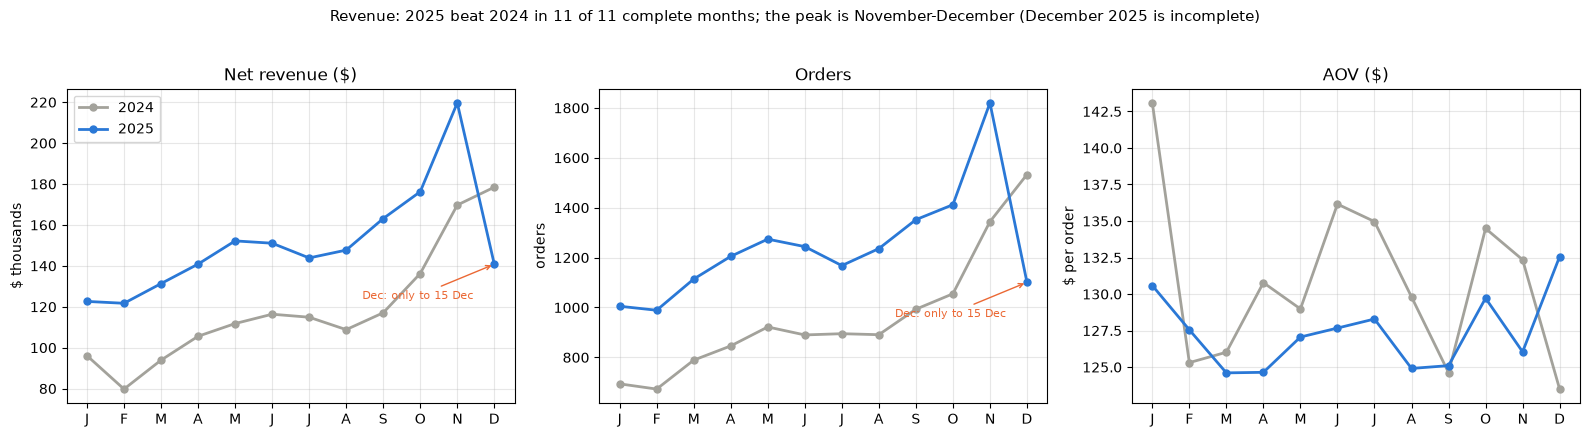

In [7]:
monthly = (clean.groupby(["year", clean["invoice_date"].dt.month])
           .apply(lambda g: pd.Series(compute_kpis(g)), include_groups=False)
           .reset_index().rename(columns={"invoice_date": "month_num"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, kpi, unit in zip(axes, ["Net revenue ($)", "Orders", "AOV ($)"], ["$ thousands", "orders", "$ per order"]):
    for year in (CFG.previous_year, CFG.current_year):
        data = monthly[monthly["year"] == year]
        values = data[kpi] / (1000 if "revenue" in kpi else 1)
        ax.plot(data["month_num"], values, marker="o", lw=2, ms=5, color=COLORS[str(year)], label=str(year))
    last = monthly[(monthly["year"] == CFG.current_year)].iloc[-1]
    if kpi != "AOV ($)":                       # the partial month distorts totals, not averages
        ax.annotate(f"Dec: only to {end:%d %b}", (last["month_num"], last[kpi] / (1000 if "revenue" in kpi else 1)),
                    xytext=(-95, -25), textcoords="offset points", fontsize=8, color=COLORS["accent"],
                    arrowprops=dict(arrowstyle="->", color=COLORS["accent"]))
    ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
    ax.set_ylabel(unit); ax.grid(alpha=0.3); ax.set_title(kpi)
axes[0].legend()
rev = monthly.pivot(index="month_num", columns="year", values="Net revenue ($)").iloc[:11]   # complete months only
months_up = int((rev[CFG.current_year] > rev[CFG.previous_year]).sum())
fig.suptitle(f"Revenue: 2025 beat 2024 in {months_up} of 11 complete months; the peak is November-December "
             f"(December 2025 is incomplete)", fontsize=11, y=1.03)
plt.tight_layout(); plt.show()

Notice how the December 2025 point drops: that is the **partial month**, not a crisis. Revenue and orders follow the same seasonal shape in both years (Nov-Dec peak), while AOV is roughly flat: growth comes from **more orders**, not bigger baskets.

---
## 8. Cohort retention: do customers come back?

A **cohort** is a group of customers who started in the same month. For each cohort we compute the share that bought again 1, 2, 3... months after signing up. This separates "we are growing because we buy new customers" from "we are growing because customers stay".

Two classic traps:
- Use the **signup date from the customer master**, not the first purchase in the export: customers who joined before 2024 would otherwise look like new 2024-01 customers.
- Recent cohorts have had **less time** to come back; cells that are not observable yet are left empty, not counted as zero.

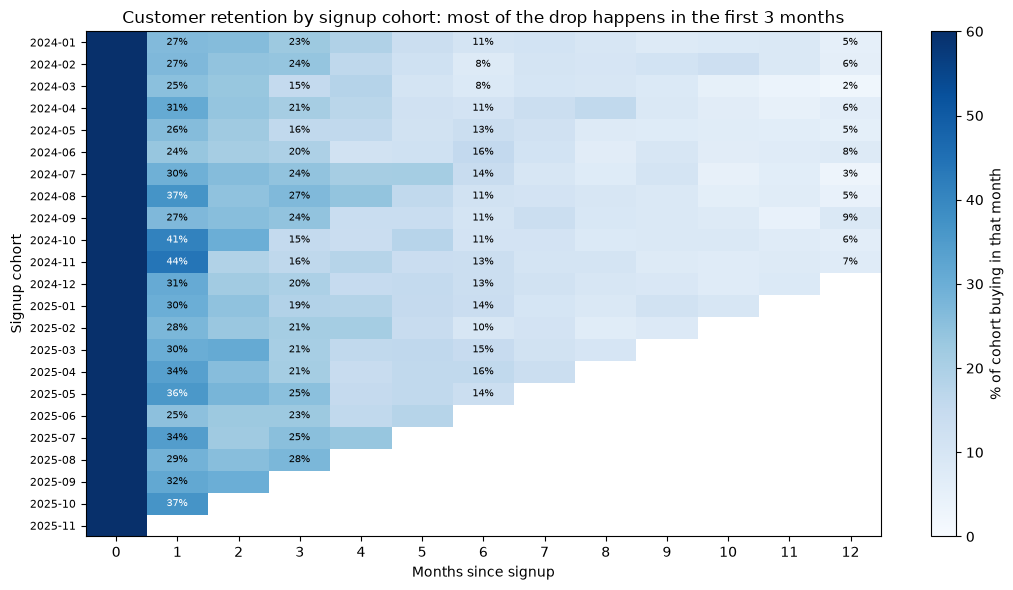

Average share of a cohort buying N months after signup (%):
                     2024  2025
months_since_signup            
1                    30.7  31.3
2                    23.9  25.9
3                    20.4  22.8
6                    11.7  13.5
12                    5.7   NaN


In [8]:
known_sales = clean[~clean["is_return"] & clean["customer_id"].notna()].merge(customers, on="customer_id", how="left")
known_sales["cohort"] = known_sales["signup_date"].dt.to_period("M")
known_sales = known_sales[known_sales["cohort"] >= pd.Period("2024-01", "M")]          # cohorts fully inside the export
known_sales["months_since_signup"] = (known_sales["month"] - known_sales["cohort"]).apply(lambda d: d.n)

cohort_size = customers.assign(cohort=customers["signup_date"].dt.to_period("M")).groupby("cohort").size()
active = known_sales.groupby(["cohort", "months_since_signup"])["customer_id"].nunique().unstack()
retention = active.div(cohort_size.reindex(active.index), axis=0)
last_month = pd.Period(CFG.extract_end, "M") - 1                                        # last COMPLETE month
for cohort in retention.index:                                                          # hide not-yet-observable cells
    retention.loc[cohort, retention.columns > (last_month - cohort).n] = np.nan
retention = retention.loc[: last_month, :12]

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(retention.to_numpy() * 100, cmap="Blues", aspect="auto", vmin=0, vmax=60)
ax.set_xticks(range(retention.shape[1]), retention.columns)
ax.set_yticks(range(len(retention)), [str(p) for p in retention.index], fontsize=8)
ax.set_xlabel("Months since signup"); ax.set_ylabel("Signup cohort")
for (i, j), v in np.ndenumerate(retention.to_numpy()):
    if not np.isnan(v) and j in (1, 3, 6, 12):
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.35 else "black")
fig.colorbar(im, ax=ax, label="% of cohort buying in that month")
ax.set_title("Customer retention by signup cohort: most of the drop happens in the first 3 months")
plt.tight_layout(); plt.show()

curve = pd.DataFrame({str(y): retention[retention.index.year == y].mean() for y in (2024, 2025)})
print("Average share of a cohort buying N months after signup (%):")
print((100 * curve.loc[[1, 2, 3, 6, 12]]).round(1).to_string())

Month 0 is always high (the signup purchase). The key numbers for the memo are the **month-1** and **month-3** retention: they tell the manager how quickly customers drop off, and whether 2025 cohorts behave differently from 2024 cohorts (in the table above, month 12 is only observable for 2024 cohorts).

---
## 9. Segment breakdowns: category, channel, region

Totals hide where things happen. One reusable function computes the same KPIs **per segment**, like-for-like, with the share of revenue and the growth vs last year.

In [9]:
def segment_table(df: pd.DataFrame, by: str) -> pd.DataFrame:
    """Like-for-like KPIs per segment: revenue share, YoY growth, AOV, return rate."""
    curr = window(df, CFG.current_year).groupby(by).apply(lambda g: pd.Series(compute_kpis(g)), include_groups=False)
    prev = window(df, CFG.previous_year).groupby(by).apply(lambda g: pd.Series(compute_kpis(g)), include_groups=False)
    table = pd.DataFrame({
        "net_revenue_2025 ($k)": curr["Net revenue ($)"] / 1000,
        "share_of_revenue_%": 100 * curr["Net revenue ($)"] / curr["Net revenue ($)"].sum(),
        "yoy_growth_%": 100 * (curr["Net revenue ($)"] / prev["Net revenue ($)"] - 1),
        "AOV_2025 ($)": curr["AOV ($)"],
        "return_rate_2025_%": curr["Return rate (%)"],
    })
    return table.sort_values("net_revenue_2025 ($k)", ascending=False).round(1)


by_category, by_channel, by_region = (segment_table(clean, col) for col in ["category", "channel", "region"])
display(by_category, by_channel, by_region)

,net_revenue_2025 ($k),share_of_revenue_%,yoy_growth_%,AOV_2025 ($),return_rate_2025_%
category,,,,,
Lighting,451.6,24.9,35.0,105.3,4.8
Garden,437.5,24.2,69.8,52.8,4.5
Kitchen,345.8,19.1,36.8,53.5,4.5
Furniture,261.5,14.4,19.8,281.4,4.7
Bedding,188.6,10.4,7.5,56.5,4.8
Decor,126.3,7.0,30.0,24.3,4.3


,net_revenue_2025 ($k),share_of_revenue_%,yoy_growth_%,AOV_2025 ($),return_rate_2025_%
channel,,,,,
web,862.8,47.6,27.3,125.8,3.2
app,565.9,31.2,45.6,128.1,3.2
marketplace,382.5,21.1,42.0,129.3,9.5


,net_revenue_2025 ($k),share_of_revenue_%,yoy_growth_%,AOV_2025 ($),return_rate_2025_%
region,,,,,
North,527.0,29.1,36.4,131.3,4.5
South,413.1,22.8,24.6,122.2,5.4
East,398.4,22.0,62.0,129.2,4.4
West,314.9,17.4,29.8,126.6,4.2
International,157.9,8.7,22.0,124.8,4.4


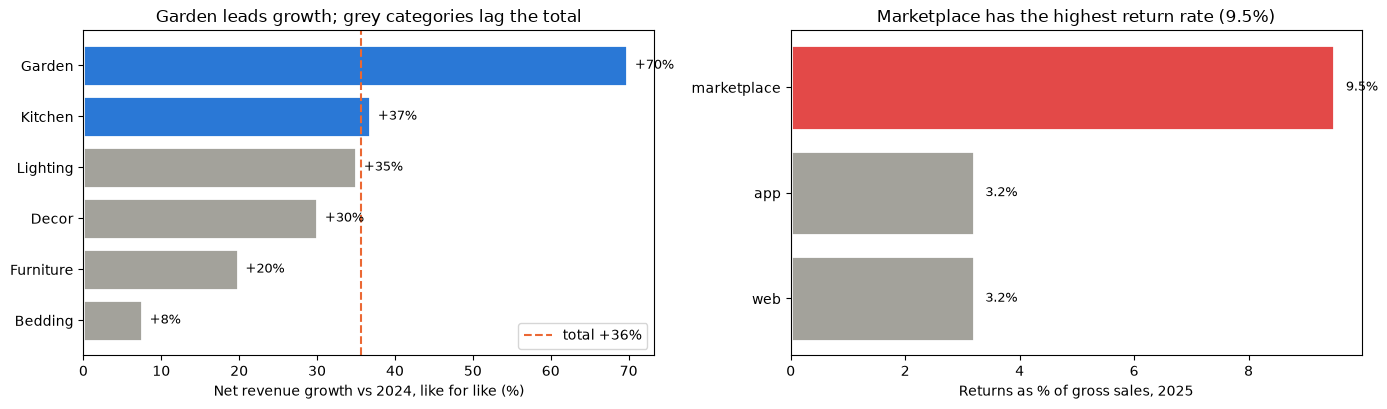

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
growth = by_category["yoy_growth_%"].sort_values()
total_growth = yoy.loc["Net revenue ($)", "change %"]
axes[0].barh(growth.index, growth, color=[COLORS["2025"] if g >= total_growth else COLORS["2024"] for g in growth],
             edgecolor="white", linewidth=2)
axes[0].axvline(total_growth, color=COLORS["accent"], ls="--", label=f"total {total_growth:+.0f}%")
for y, g in enumerate(growth):
    axes[0].text(g + 1, y, f"{g:+.0f}%", va="center", fontsize=9)
axes[0].set_xlabel("Net revenue growth vs 2024, like for like (%)"); axes[0].legend(loc="lower right")
axes[0].set_title(f"{growth.idxmax()} leads growth; grey categories lag the total")

rates = by_channel["return_rate_2025_%"].sort_values()
axes[1].barh(rates.index, rates, color=[COLORS["bad"] if r == rates.max() else COLORS["2024"] for r in rates],
             edgecolor="white", linewidth=2)
for y, r in enumerate(rates):
    axes[1].text(r + 0.2, y, f"{r:.1f}%", va="center", fontsize=9)
axes[1].set_xlabel("Returns as % of gross sales, 2025")
axes[1].set_title(f"{rates.idxmax().capitalize()} has the highest return rate ({rates.max():.1f}%)")
plt.tight_layout(); plt.show()

Two segment findings go straight into the memo: **which categories drive (or drag) growth** and the **marketplace return rate**, which is well above the other channels. Returns cost money twice (shipping and handling), so a channel's net contribution is lower than its gross sales suggest.

---
## 10. Pareto / ABC analysis: where is the money concentrated?

The **Pareto principle** ("80/20 rule") says a small share of products or customers often makes most of the revenue. **ABC analysis** turns this into an action list used by buyers and inventory planners:
- **A** items: the products that together make the first 80% of revenue. Never out of stock, review weekly.
- **B** items: the next 15%. Standard care.
- **C** items: the last 5%. Candidates for range reduction or made-to-order.

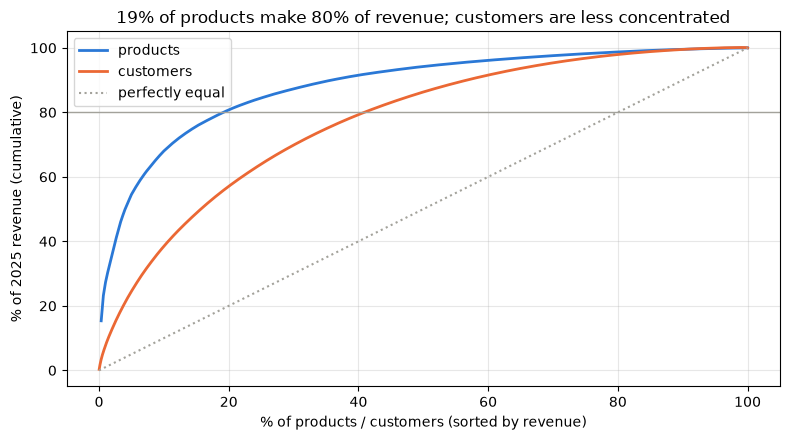

,n_products,revenue,% of products,% of revenue
abc_class,,,,
A,58,1451785.14,19.3,80.2
B,104,269776.63,34.7,14.9
C,138,89672.84,46.0,5.0


Share of 2025 revenue from the top 1% / 10% / 20% of customers: 8% / 38% / 57%


In [11]:
def abc_analysis(values: pd.Series, cutoffs=CFG.abc_cutoffs) -> pd.DataFrame:
    """Sort items by value, compute cumulative share and assign A/B/C classes."""
    table = values.sort_values(ascending=False).to_frame("revenue")
    table["cum_share"] = table["revenue"].cumsum() / table["revenue"].sum()
    table["abc_class"] = np.where(table["cum_share"].shift(fill_value=0) < cutoffs[0], "A",
                                  np.where(table["cum_share"].shift(fill_value=0) < cutoffs[1], "B", "C"))
    return table


current = window(clean, CFG.current_year)
products = abc_analysis(current.groupby("sku")["line_value"].sum())
abc_summary = products.groupby("abc_class").agg(n_products=("revenue", "size"), revenue=("revenue", "sum"))
abc_summary["% of products"] = (100 * abc_summary["n_products"] / abc_summary["n_products"].sum()).round(1)
abc_summary["% of revenue"] = (100 * abc_summary["revenue"] / abc_summary["revenue"].sum()).round(1)

cust_rev = current.dropna(subset=["customer_id"]).groupby("customer_id")["line_value"].sum().sort_values(ascending=False)
top_share = {p: 100 * cust_rev.head(int(len(cust_rev) * p / 100)).sum() / cust_rev.sum() for p in (1, 10, 20)}

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(1, len(products) + 1) / len(products) * 100
ax.plot(x, products["cum_share"] * 100, color=COLORS["2025"], lw=2, label="products")
cx = np.arange(1, len(cust_rev) + 1) / len(cust_rev) * 100
ax.plot(cx, cust_rev.cumsum() / cust_rev.sum() * 100, color=COLORS["accent"], lw=2, label="customers")
ax.plot([0, 100], [0, 100], color=COLORS["2024"], ls=":", label="perfectly equal")
ax.axhline(80, color=COLORS["2024"], lw=1)
ax.set_xlabel("% of products / customers (sorted by revenue)"); ax.set_ylabel("% of 2025 revenue (cumulative)")
a_share = abc_summary.loc["A", "% of products"]
ax.set_title(f"{a_share:.0f}% of products make 80% of revenue; customers are less concentrated")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
display(abc_summary)
print("Share of 2025 revenue from the top 1% / 10% / 20% of customers:",
      " / ".join(f"{v:.0f}%" for v in top_share.values()))

---
## 11. Checking a claim: "loyalty members spend 20% more"

Marketing's claim is the most dangerous number in the request, because a budget decision depends on it. A careful analyst answers three questions in order:

1. **Is the difference real or noise?** -> a significance test and a confidence interval, at the right **unit of analysis** (customers, not order lines: many orders from the same big spender are not independent evidence).
2. **How big is it?** -> report the effect size with its uncertainty, not just a p-value.
3. **Is it *caused* by the program?** -> members **chose** to join. If big spenders join more often, members spent more **before** joining too (selection bias). Compare the **change** for members with the change for non-members over the same months (**difference-in-differences**).

> Ideally the program would have been launched as an **A/B test** (random invitation). See `../03_Machine_Learning/11_ab_testing/` for how that works; here we do the best we can with observational data.

In [12]:
orders = (clean[~clean["is_return"]].dropna(subset=["customer_id"])
          .groupby("invoice_no").agg(customer_id=("customer_id", "first"), date=("invoice_date", "first"),
                                     value=("line_value", "sum"), member=("loyalty_member", "first")))
members = set(orders.loc[orders["member"], "customer_id"])            # customers who joined the program

# Step 1+2: the claim as marketing computed it (orders since launch, member orders vs non-member orders)
since_launch = orders[orders["date"] >= CFG.loyalty_launch]
naive = since_launch.groupby("member")["value"].mean()
print(f"Order-level AOV since launch: members ${naive[True]:.2f} vs non-members ${naive[False]:.2f} "
      f"-> {100 * (naive[True] / naive[False] - 1):+.1f}%  (the marketing number)")

# Right unit of analysis: one AOV per customer
per_customer = since_launch.groupby("customer_id").agg(aov=("value", "mean"))
per_customer["member"] = per_customer.index.isin(members)
m_aov, n_aov = per_customer.loc[per_customer["member"], "aov"], per_customer.loc[~per_customer["member"], "aov"]
welch = stats.ttest_ind(m_aov, n_aov, equal_var=False)                # Welch t-test: unequal variances
mwu = stats.mannwhitneyu(m_aov, n_aov)                                 # rank-based: robust to skew/outliers

rng = np.random.default_rng(CFG.seed)
boot = np.array([rng.choice(m_aov.to_numpy(), len(m_aov)).mean() / rng.choice(n_aov.to_numpy(), len(n_aov)).mean() - 1
                 for _ in range(CFG.n_bootstrap)])
ci_low, ci_high = np.percentile(boot, [2.5, 97.5]) * 100
print(f"Customer-level: {len(m_aov)} members vs {len(n_aov)} non-members | "
      f"difference {100 * (m_aov.mean() / n_aov.mean() - 1):+.1f}% (95% CI {ci_low:+.1f}% to {ci_high:+.1f}%)")
print(f"Welch t-test p = {welch.pvalue:.2g} | Mann-Whitney p = {mwu.pvalue:.2g}")

Order-level AOV since launch: members $143.69 vs non-members $120.40 -> +19.3%  (the marketing number)


Customer-level: 459 members vs 2130 non-members | difference +18.1% (95% CI +11.4% to +26.1%)
Welch t-test p = 7.7e-07 | Mann-Whitney p = 1.1e-11


The difference is **statistically significant**: it is very unlikely to be noise. But significance only says *"members and non-members differ"*, not *why*. Now the causal question: did members already spend more **before** the program existed?

In [13]:
pre = orders[(orders["date"] >= "2025-01-01") & (orders["date"] < CFG.loyalty_launch)]       # H1 2025, before launch
post = orders[(orders["date"] >= "2025-10-09")]                                              # after everyone had joined
both = (pre.groupby("customer_id")["value"].mean().rename("aov_pre").to_frame()
        .join(post.groupby("customer_id")["value"].mean().rename("aov_post"), how="inner"))  # bought in both periods
both["member"] = both.index.isin(members)
both["log_change"] = np.log(both["aov_post"] / both["aov_pre"])        # log ratio: robust to a few huge baskets

summary = both.groupby("member").agg(n_customers=("aov_pre", "size"), aov_pre=("aov_pre", "mean"),
                                    aov_post=("aov_post", "mean"),
                                    typical_change_pct=("log_change", lambda x: 100 * (np.exp(x.mean()) - 1)))
summary.index = summary.index.map({True: "members", False: "non-members"})
display(summary.round(1))


def did(frame: pd.DataFrame) -> float:
    """Difference-in-differences (%): typical AOV change of members relative to non-members."""
    g = frame.groupby("member")["log_change"].mean()
    return 100 * (np.exp(g.loc[True] - g.loc[False]) - 1)


did_estimate = did(both)
idx_m, idx_n = np.flatnonzero(both["member"]), np.flatnonzero(~both["member"])
did_boot = np.array([did(both.iloc[np.concatenate([rng.choice(idx_m, len(idx_m)), rng.choice(idx_n, len(idx_n))])])
                     for _ in range(1000)])
did_low, did_high = np.percentile(did_boot, [2.5, 97.5])
pre_gap = 100 * (summary.loc["members", "aov_pre"] / summary.loc["non-members", "aov_pre"] - 1)
print(f"Before the program existed, future members already had a {pre_gap:+.1f}% higher AOV (selection).")
print(f"Difference-in-differences (program effect on AOV): {did_estimate:+.1f}%, 95% CI {did_low:+.1f}% to {did_high:+.1f}%")

,n_customers,aov_pre,aov_post,typical_change_pct
member,,,,
non-members,424,119.7,119.3,-2.9
members,131,148.4,143.9,-10.7


Before the program existed, future members already had a +24.0% higher AOV (selection).
Difference-in-differences (program effect on AOV): -8.0%, 95% CI -23.6% to +10.0%


**The honest answer to marketing** (check the numbers above):
- The order-level gap that marketing quoted is real in the data, and significant at customer level.
- But the gap existed **before** the program: in the first half of 2025 the future members already had a higher AOV (about +24%, even more than today's +19% gap). The customers who joined were simply bigger spenders. That is **selection bias**, not program impact.
- The difference-in-differences estimate of the program's own effect on AOV is **much smaller** (here even slightly negative), and its 95% confidence interval is wide and includes 0: with this data we cannot tell whether the program changes basket size at all. Only about 130 members bought both before and after joining, which is too few to detect a small effect.
- Recommendation: do not justify the program budget with "+20% per order". Run a **randomised test** (invite a random half of eligible customers) for the next phase, and also measure order *frequency*, not only basket size.

---
## 12. The auto-generated memo for the manager

The memo is generated **from the variables computed above** (no number is typed by hand), so it can be re-run next month and it can never disagree with the tables. Structure: headline -> key numbers -> findings -> recommendations -> data notes. In a real team this would be pasted into a slide, a Confluence page or an email.

In [14]:
def fmt_money(x: float) -> str:
    """$1.23M / $456k / -$166k"""
    sign = "-" if x < 0 else ""
    return f"{sign}${abs(x) / 1e6:.2f}M" if abs(x) >= 1e6 else f"{sign}${abs(x) / 1e3:,.0f}k"


net_growth = yoy.loc["Net revenue ($)", "change %"]
cust_growth = yoy.loc["Active customers", "change %"]
aov_change = yoy.loc["AOV ($)", "change %"]
best_cat, worst_cat = by_category["yoy_growth_%"].idxmax(), by_category["yoy_growth_%"].idxmin()
n_cat_up = int((by_category["yoy_growth_%"] > 0).sum())
worst_growth = by_category.loc[worst_cat, "yoy_growth_%"]
lag_text = (f"investigate the decline in **{worst_cat}**" if worst_growth < 0 else
            f"investigate why **{worst_cat}** grows only {worst_growth:+.0f}% vs {yoy.loc['Net revenue ($)', 'change %']:+.0f}% overall")
worst_channel = by_channel["return_rate_2025_%"].idxmax()
dq_money = bridge["change"].iloc[1:5].sum()                # duplicates + test orders + dates + price typos
guest_pct = dq_report.set_index("check").loc["Missing customer_id (guest checkout)", "% of rows"]
m1 = curve.loc[1, "2025"]; m3 = curve.loc[3, "2025"]

memo = f"""
### NordHome 2025 review (data to {end:%d %b %Y}): findings & recommendations

**Headline:** net revenue is **{net_growth:+.0f}%** vs the same period of 2024 ({fmt_money(kpi_curr['Net revenue ($)'])} vs {fmt_money(kpi_prev['Net revenue ($)'])}), driven by **more active customers ({cust_growth:+.0f}%)** who also order more often; the average order value changed by {aov_change:+.1f}%.

**Key numbers (1 Jan-{end:%d %b}, like for like)**
- Orders: {kpi_curr['Orders']:,.0f} ({yoy.loc['Orders', 'change %']:+.0f}%) | AOV: ${kpi_curr['AOV ($)']:.0f} | Return rate: {kpi_curr['Return rate (%)']:.1f}% (2024: {kpi_prev['Return rate (%)']:.1f}%)
- Retention of 2025 signups: {m1:.0%} buy again in month 1, {m3:.0%} in month 3
- {abc_summary.loc['A', '% of products']:.0f}% of products ("A" items) make 80% of revenue; the top 10% of customers make {top_share[10]:.0f}%

**Findings**
1. {n_cat_up} of {len(by_category)} categories grew, led by **{best_cat}** ({by_category.loc[best_cat, 'yoy_growth_%']:+.0f}%); **{worst_cat}** is the weakest category ({by_category.loc[worst_cat, 'yoy_growth_%']:+.0f}%).
2. **{worst_channel.capitalize()}** has a return rate of {by_channel.loc[worst_channel, 'return_rate_2025_%']:.1f}%, vs {by_channel.drop(worst_channel)['return_rate_2025_%'].mean():.1f}% on our own channels: its net contribution is lower than gross sales suggest.
3. Most customer loss happens in the first months after signup (month-1 retention {m1:.0%}).
4. The loyalty claim does not hold up: members' orders are {100 * (naive[True] / naive[False] - 1):+.0f}% larger, but future members already spent {pre_gap:+.0f}% more **before** the program. The program's own effect on AOV is estimated at {did_estimate:+.1f}% (95% CI {did_low:+.1f}% to {did_high:+.1f}%).

**Recommendations**
1. Protect availability of the A items (stock alerts, weekly review); review the C tail for range reduction.
2. Invest in **{best_cat}** for spring; {lag_text} (assortment, pricing, competitors).
3. Work with the marketplace on return reasons (product data, sizing, packaging) before scaling it further.
4. Add a second-purchase journey for new customers (welcome series in weeks 2-6).
5. Do **not** budget the loyalty program on "{100 * (naive[True] / naive[False] - 1):+.0f}% per order"; run a randomised invitation test in Q1 and measure frequency as well as AOV.

**Data notes:** December 2025 is incomplete (data to {end:%d %b}). Cleaning removed duplicates, test orders and impossible dates and corrected price typos, together changing raw revenue by {fmt_money(dq_money)}. Guest checkouts ({guest_pct:.1f}% of lines) are in revenue but not in customer metrics. Definitions: see the KPI table.
"""
display(Markdown(memo))

REPORT_DIR = Path(tempfile.mkdtemp(prefix="eda_report_"))     # real life: a shared drive, Confluence or the BI tool
(REPORT_DIR / "nordhome_2025_memo.md").write_text(memo)
dq_report.to_csv(REPORT_DIR / "data_quality_report.csv", index=False)
yoy.round(2).to_csv(REPORT_DIR / "kpis_like_for_like.csv")
print("Saved:", sorted(p.name for p in REPORT_DIR.iterdir()))


### NordHome 2025 review (data to 15 Dec 2025): findings & recommendations

**Headline:** net revenue is **+36%** vs the same period of 2024 ($1.81M vs $1.34M), driven by **more active customers (+28%)** who also order more often; the average order value changed by -2.8%.

**Key numbers (1 Jan-15 Dec, like for like)**
- Orders: 14,920 (+39%) | AOV: $127 | Return rate: 4.6% (2024: 5.0%)
- Retention of 2025 signups: 31% buy again in month 1, 23% in month 3
- 19% of products ("A" items) make 80% of revenue; the top 10% of customers make 38%

**Findings**
1. 6 of 6 categories grew, led by **Garden** (+70%); **Bedding** is the weakest category (+8%).
2. **Marketplace** has a return rate of 9.5%, vs 3.2% on our own channels: its net contribution is lower than gross sales suggest.
3. Most customer loss happens in the first months after signup (month-1 retention 31%).
4. The loyalty claim does not hold up: members' orders are +19% larger, but future members already spent +24% more **before** the program. The program's own effect on AOV is estimated at -8.0% (95% CI -23.6% to +10.0%).

**Recommendations**
1. Protect availability of the A items (stock alerts, weekly review); review the C tail for range reduction.
2. Invest in **Garden** for spring; investigate why **Bedding** grows only +8% vs +36% overall (assortment, pricing, competitors).
3. Work with the marketplace on return reasons (product data, sizing, packaging) before scaling it further.
4. Add a second-purchase journey for new customers (welcome series in weeks 2-6).
5. Do **not** budget the loyalty program on "+19% per order"; run a randomised invitation test in Q1 and measure frequency as well as AOV.

**Data notes:** December 2025 is incomplete (data to 15 Dec). Cleaning removed duplicates, test orders and impossible dates and corrected price typos, together changing raw revenue by -$166k. Guest checkouts (2.5% of lines) are in revenue but not in customer metrics. Definitions: see the KPI table.


Saved: ['data_quality_report.csv', 'kpis_like_for_like.csv', 'nordhome_2025_memo.md']


Read the memo once as the manager would: every sentence is a number with a comparison, every finding has a recommendation, and the data notes say what the numbers do **not** include. Check that each statement matches the tables above; that is the reviewer's job before anything is sent.

---
## 13. QA checks on the report numbers

A wrong number in a leadership deck costs trust that takes months to rebuild. Analysts automate a few **consistency checks** that must pass before the report goes out.

In [15]:
def test_kpis_are_internally_consistent():
    k = kpi_curr
    assert abs(k["AOV ($)"] * k["Orders"] - k["Gross sales ($)"]) < 1e-6 * k["Gross sales ($)"]
    assert abs(k["Gross sales ($)"] + k["Returns ($)"] - k["Net revenue ($)"]) < 1e-6


def test_segments_add_up_to_total():
    for table in (by_category, by_channel, by_region):
        assert abs(table["net_revenue_2025 ($k)"].sum() * 1000 - kpi_curr["Net revenue ($)"]) < 0.001 * kpi_curr["Net revenue ($)"]


def test_revenue_bridge_reconciles():
    assert abs(bridge["revenue_after_step"].iloc[-1] - clean["line_value"].sum()) < 1e-6 * abs(clean["line_value"].sum())


def test_no_test_orders_or_future_dates_left():
    assert not clean["customer_id"].eq("TEST").any()
    assert clean["invoice_date"].max() < pd.Timestamp(CFG.extract_end) + pd.Timedelta(days=1)


def test_retention_is_a_share():
    values = retention.to_numpy()
    assert np.nanmin(values) >= 0 and np.nanmax(values) <= 1


def test_abc_classes_cover_all_revenue():
    assert abs(abc_summary["% of revenue"].sum() - 100) < 0.5
    assert abc_summary.loc["A", "% of revenue"] >= 79


for test in [test_kpis_are_internally_consistent, test_segments_add_up_to_total, test_revenue_bridge_reconciles,
             test_no_test_orders_or_future_dates_left, test_retention_is_a_share, test_abc_classes_cover_all_revenue]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_kpis_are_internally_consistent
PASSED  test_segments_add_up_to_total
PASSED  test_revenue_bridge_reconciles
PASSED  test_no_test_orders_or_future_dates_left
PASSED  test_retention_is_a_share
PASSED  test_abc_classes_cover_all_revenue


---
## 14. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Report config | extract date, windows and thresholds in one dataclass | Recurring monthly/quarterly reports |
| Data-quality report | rows **and revenue** affected per issue, with a decision | Finance reconciliation, data contracts |
| Revenue bridge | raw -> clean step by step | "Why doesn't your number match finance?" |
| KPI definitions | one table + one `compute_kpis()` function | Metric layers / semantic layers (dbt metrics, Looker) |
| Like-for-like YoY | same calendar window in both years | Retail and e-commerce reporting |
| Partial-period flag | December annotated as incomplete | Every dashboard with a "current month" |
| Cohort retention | signup cohorts from master data, unobservable cells hidden | Subscription, e-commerce, apps |
| Segments | same KPIs per category/channel/region | Business reviews |
| Pareto / ABC | A/B/C classes for products, customer concentration | Inventory planning, key-account management |
| Claim check | customer-level tests, bootstrap CI, pre-period check, diff-in-diff | Marketing/product analytics |
| Generated memo + QA tests | numbers flow from code into text; consistency asserts | Reproducible reporting |

### Practice exercises
1. Change `extract_end` to `"2025-11-30"` and re-run. Which numbers in the memo change, and does the naive vs like-for-like gap shrink?
2. Add **gross margin**: assume a cost price of 55% of the unit price for Furniture and 40% for everything else. Which category is most profitable, not just biggest?
3. Compute retention as **revenue retention** (revenue of the cohort in month k / revenue in month 0). How does the story change?
4. In Section 11, test whether members buy more **often** (orders per customer per month) with the same pre/post design.
5. Turn `compute_kpis` and `segment_table` into a small module with tests, following `../01_Python/04_industry_from_notebook_to_production_code.ipynb`.

### Resources (checked)
- UCI Machine Learning Repository, *Online Retail II* (the real dataset this simulation imitates): https://archive.ics.uci.edu/dataset/502/online+retail+ii
- Kaggle, *Online Retail II UCI* dataset and community notebooks (cohort / RFM analyses): https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci
- pandas user guide, *Group by: split-apply-combine*: https://pandas.pydata.org/docs/user_guide/groupby.html
- SciPy `ttest_ind` (Welch's test with `equal_var=False`): https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html
- SciPy `mannwhitneyu`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html
- Causal Inference: The Mixtape (Scott Cunningham), difference-in-differences chapter: https://mixtape.scunning.com/09-difference_in_differences
- Storytelling with Data (Cole Nussbaumer Knaflic), chart principles used here: https://www.storytellingwithdata.com/
- ABC analysis (inventory classification), overview: https://en.wikipedia.org/wiki/ABC_analysis

### Related notebooks in this repo
- `07_eda.ipynb`: the general EDA workflow on a clean dataset
- `08_statistics.ipynb`: t-tests, chi-square, confidence intervals in detail
- `03_pandas.ipynb`, `04_matplotlib.ipynb`: the tools used here
- `10_duckdb.ipynb`: running the same analysis as SQL
- `../03_Machine_Learning/11_ab_testing/02_industry_ab_test_analysis_report.ipynb`: how a randomised test would settle the loyalty question